**Install & Imports:**

In [1]:
!pip -q install ultralytics

In [10]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import ultralytics
from ultralytics import FastSAM
from pathlib import Path
from tqdm.auto import tqdm
from torch.distributed import Work

print("OpenCV:", cv2.__version__)
print("Torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

OpenCV: 4.14.0
Torch: 2.14.1+cu130 | CUDA: True


**Download Dataset API:**

In [3]:
RECORD_ID = "23376472"
API = f"https://zenodo.org/api/records/{RECORD_ID}"
DATA_DIR = Path("data/zenodo_colonies")
DATA_DIR.mkdir(exist_ok=True, parents=True)

r = requests.get(API, timeout=60)
r.raise_for_status()
rec = r.json()
files = rec["files"]
print("Title:", rec["metadata"]["title"])
print("Files:", len(files))

for f in tqdm(files, desc="Download"):
  name = f["key"]
  out = DATA_DIR / name
  if out.exists() and out.stat().st_size == f["size"]:
    continue
  resp = requests.get(f["links"]["self"], timeout=300)
  resp.raise_for_status()
  out.write_bytes(resp.content)

manifest = pd.read_csv(DATA_DIR / "manifest.csv")
manifest["local_path"] = manifest["image_path"].apply(lambda x: str(DATA_DIR / x))
print("Manifest:", manifest.shape)

Title: High-Resolution agar plate image benchmark dataset for automated colony enumeration
Files: 60


Download:   0%|          | 0/60 [00:00<?, ?it/s]

Manifest: (59, 7)


**Helper Functions:**

In [16]:
def resize_max(img, max_size=1024):
  h, w = img.shape[:2]
  scale = min(1.0, max_size / max(h, w))
  if scale < 1.0:
    img = cv2.resize(img, (int(w*scale), int(h*scale)), interpolation=cv2.INTER_AREA)
  return img, scale

def find_plate_circle(gray):
  blur = cv2.GaussianBlur(gray, (9, 9), 2)
  circles = cv2.HoughCircles(
      blur, cv2.HOUGH_GRADIENT, dp=1.2, minDist=gray.shape[0] // 3,
      param1=120, param2=40,
      minRadius=gray.shape[0] // 5, maxRadius=gray.shape[0] // 2
  )

  if circles is not None:
    circles = np.uint16(np.around(circles[0]))
    x, y, r = max(circles, key=lambda c: c[2])
    return int(x), int(y), int(r)

  edges = cv2.Canny(blur, 50, 150)
  cnts, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
  if not cnts:
    return None
  cnt = max(cnts, key=cv2.contourArea)
  (x, y), r = cv2.minEnclosingCircle(cnt)
  return int(x), int(y), int(r)

def plate_mask(shape, circle, erode_px=10):
  mask = np.zeros(shape[:2], np.uint8)
  if circle is None:
    return mask
  x, y, r = circle
  cv2.circle(mask, (x, y), max(0, r - erode_px), 255, -1)
  return mask

**Load FastSAM Model:**

In [7]:
model = FastSAM("FastSAM/FastSAM-x.pt")
print("FasrSAM Model Loaded")

FasrSAM Model Loaded


**Deep Counting Function:**

In [11]:
def mask_from_fastsam(img_bgr, conf=0.3, iou=0.7, device="cuda"):
  rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
  result = model(rgb, device=device, conf=conf, iou=iou, verbose=False)
  masks = []
  if not result or result[0].masks is None:
    return masks
  mh, mw = img_bgr.shape[:2]
  for m in result[0].masks.data:
    m = m.detach().cpu().numpy()
    m = (m > 0.5).astype(np.uint8) * 255
    if m.shape[0] != mh or m.shape[1] != mw:
      m = cv2.resize(m, (mw, mh), interpolation=cv2.INTER_NEAREST)
    masks.append(m)
  return masks

def filter_colony_masks(masks, plate_m, min_area=15, max_area_ratio=0.025, min_circularity=0.3):
  plate_area = float(plate_m.sum() / 255.0) + 1.0
  max_area = plate_area * max_area_ratio
  kept = []
  for m in masks:
    inside = cv2.bitwise_and(m, plate_m)
    area = inside.sum() / 255.0
    if area < min_area or area > max_area:
      continue
    if area / (m.sum() / 255.0 + 1e-6) < 0.7:
      continue
    cnts, _ = cv2.findContours(inside, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
      continue
    c = max(cnts, key=cv2.contourArea)
    a = cv2.contourArea(c)
    peri = cv2.arcLength(c, True) + 1e-6
    circ = 4 * np.pi * a / (peri * peri)
    if circ < min_circularity:
      continue
    kept.append(inside)
  return kept

def count_colonies_dl(img_bgr):
  Work, scale = resize_max(img_bgr, 1024)
  gray = cv2.cvtColor(Work, cv2.COLOR_BGR2GRAY)
  circle = find_plate_circle(gray)
  pmask = plate_mask(Work.shape, circle, erode_px=12)

  raw_masks = mask_from_fastsam(Work)
  colonies = filter_colony_masks(raw_masks, pmask)

  overlay = Work.copy()
  for m in colonies:
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(overlay, cnts, -1, (0, 255, 0), 2)
    for c in cnts:
      M = cv2.moments(c)
      if M["m00"] > 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
        cv2.circle(overlay, (cx, cy), 2, (0, 0, 255), -1)

  return len(colonies), overlay, {"n_raw_masks": len(raw_masks), "circle": circle, "scale": scale}

def show_bgr(img, title="", ax=None):
  rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  if ax is None:
    plt.imshow(rgb)
    plt.title(title)
    plt.axis("off")
  else:
    ax.imshow(rgb)
    ax.set_title(title)
    ax.axis("off")

**Visual Test (NC + A Few Plates):**

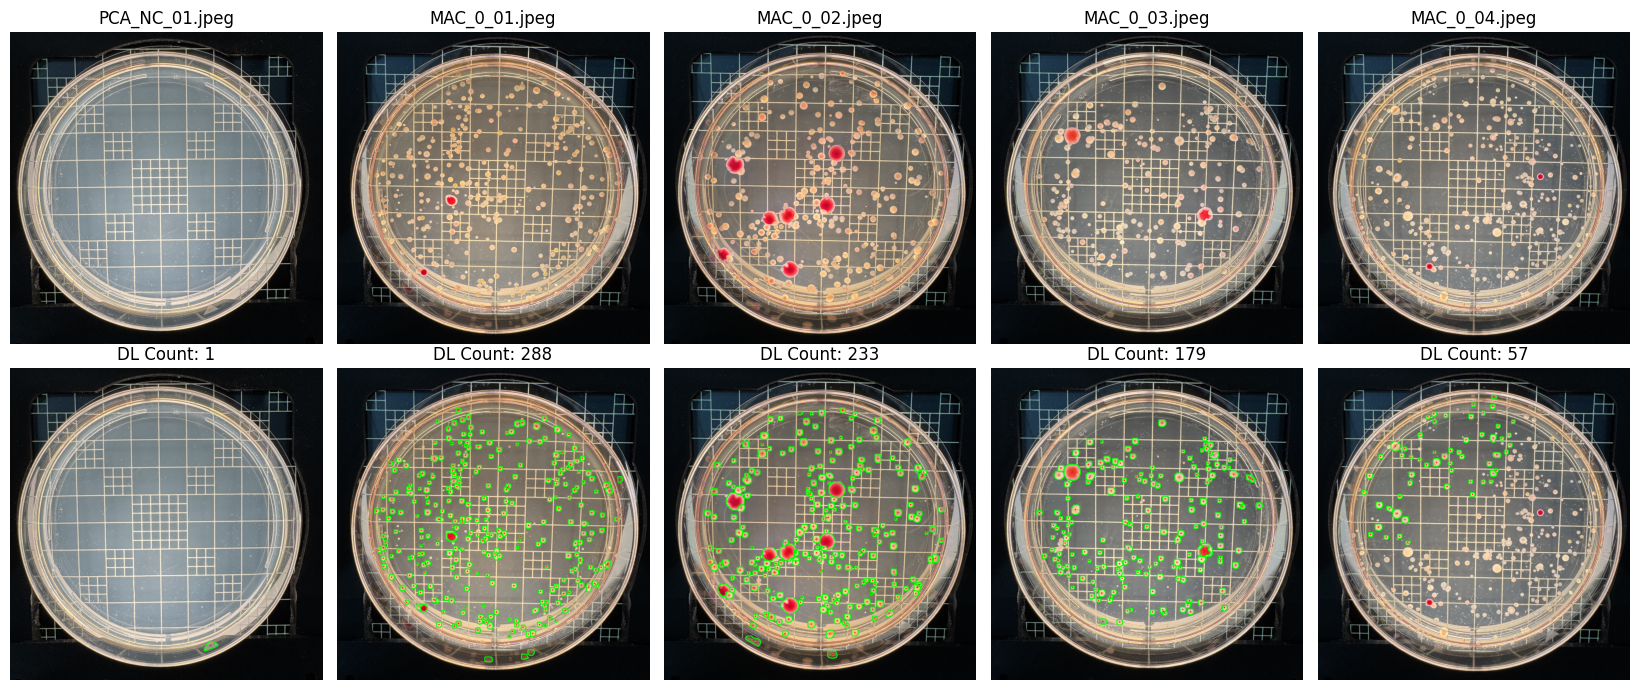

,image_path,sample_id,is_negative_control,dl_count,raw_masks
0,PCA_NC_01.jpeg,PCA_NC,True,1,7
1,MAC_0_01.jpeg,MAC_0,False,288,293
2,MAC_0_02.jpeg,MAC_0,False,233,241
3,MAC_0_03.jpeg,MAC_0,False,179,185
4,MAC_0_04.jpeg,MAC_0,False,57,177


In [12]:
samples = pd.concat([
    manifest[manifest["is_negative_control"] == True].head(1),
    manifest[manifest["is_negative_control"] == False].head(4)
])

fig, axes = plt.subplots(2, len(samples), figsize=(3.3 * len(samples), 7))
results_list = []
for i, (_, row) in enumerate(samples.iterrows()):
  img = cv2.imread(row["local_path"])
  count, overlay, dbg = count_colonies_dl(img)
  results_list.append({
      "image_path": row["image_path"],
      "sample_id": row["sample_id"],
      "is_negative_control": row["is_negative_control"],
      "dl_count": count,
      "raw_masks": dbg["n_raw_masks"],
  })
  show_bgr(img, row["image_path"], ax=axes[0, i])
  show_bgr(overlay, f"DL Count: {count}", ax=axes[1, i])

plt.tight_layout()
plt.show()
pd.DataFrame(results_list)

**Full Dataset:**

In [15]:
out_ov = DATA_DIR / "overlays_dl"
out_ov.mkdir(exist_ok=True)

rows = []
for _, row in tqdm(manifest.iterrows(), total=len(manifest)):
    img = cv2.imread(row["local_path"])
    if img is None:
        rows.append({**row.to_dict(), "dl_count": None, "raw_masks": None, "error": "read_fail"})
        continue
    try:
        count, overlay, dbg = count_colonies_dl(img)
        cv2.imwrite(str(out_ov / row["image_path"]), overlay)
        rows.append({
            **row.to_dict(),
            "dl_count": count,
            "raw_masks": dbg["n_raw_masks"],
            "error": "",
        })
    except Exception as e:
        rows.append({
            **row.to_dict(),
            "dl_count": None,
            "raw_masks": None,
            "error": str(e),
        })

dl_df = pd.DataFrame(rows)
dl_df.to_csv(DATA_DIR / "colony_counts_dl.csv", index=False)
print(dl_df[["image_path", "sample_id", "is_negative_control", "dl_count", "error"]].head(12))
print("Saved:", DATA_DIR / "colony_counts_dl.csv")

nc = dl_df.loc[dl_df["is_negative_control"] == True, "dl_count"]
pos = dl_df.loc[dl_df["is_negative_control"] == False, "dl_count"]
print("Mean DL (Non-NC):", pos.mean())
print("Mean DL (NC):", nc.mean())
print(dl_df.loc[dl_df["is_negative_control"] == True, ["image_path", "dl_count"]])

  0%|          | 0/59 [00:00<?, ?it/s]

       image_path sample_id  is_negative_control  dl_count error
0   MAC_0_01.jpeg     MAC_0                False       288      
1   MAC_0_02.jpeg     MAC_0                False       233      
2   MAC_0_03.jpeg     MAC_0                False       179      
3   MAC_0_04.jpeg     MAC_0                False        57      
4   MAC_1_01.jpeg     MAC_1                False        77      
5   MAC_1_02.jpeg     MAC_1                False        35      
6   MAC_1_03.jpeg     MAC_1                False        31      
7   MAC_1_04.jpeg     MAC_1                False       152      
8   MAC_2_01.jpeg     MAC_2                False         5      
9   MAC_2_02.jpeg     MAC_2                False        12      
10  MAC_3_01.jpeg     MAC_3                False        10      
11  MAC_3_02.jpeg     MAC_3                False         2      
Saved: data/zenodo_colonies/colony_counts_dl.csv
Mean DL (Non-NC): 65.35087719298245
Mean DL (NC): 0.5
        image_path  dl_count
46  PCA_NC_01.jpeg     